# Phytate PMF analysis

Loads the extracted per-condition data into a table-of-tables indexed by `(ionic_strength, pH)`.
Each cell (`pmf`, `potential_all`, `potential_peptide`, `shape`, `charge`) holds that quantity's own `[r, ...]` DataFrame on its native grid.

Regenerate the CSVs first if needed: `python plot_pmf.py` (writes `all_pmfs.csv`) and `python extract_data.py` (writes `charge.csv`, `polymer_shape.csv`, `potential.csv`).

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
KEY = ["ionic_strength", "pH"]

def _by_condition(df, cols):
    """(ionic_strength, pH) -> sub-frame of [r, *cols], sorted by r."""
    return {cond: g.sort_values("r")[["r", *cols]].reset_index(drop=True)
            for cond, g in df.groupby(KEY)}


def load(data_dir="."):
    """Merge the extracted CSVs into a table-of-tables indexed by (ionic_strength, pH).

    Columns pmf, potential_all, potential_peptide, shape, charge each hold that
    quantity's own [r, ...] DataFrame (or None where a condition is missing).
    """
    d = Path(data_dir)
    pmf = pd.read_csv(d / "all_pmfs.csv")
    charge = pd.read_csv(d / "charge.csv")
    shape = pd.read_csv(d / "polymer_shape.csv")
    pot = pd.read_csv(d / "potential.csv")

    # charge.csv is long (one row per selection) -> wide, one column per selection
    charge = (charge.pivot_table(index=KEY + ["r"], columns="selection", values="charge")
                    .rename(columns={"molecule peptide": "charge_peptide",
                                     "atomtype INO": "charge_phytate"})
                    .reset_index())

    shape_cols = [c for c in shape.columns if c not in KEY + ["r"]]
    quantities = {
        "pmf": _by_condition(pmf, ["pmf_kT", "stderr_kT"]),
        "potential_all": _by_condition(pot, ["potential_all_mV"]),
        "potential_peptide": _by_condition(pot, ["potential_peptide_mV"]),
        "shape": _by_condition(shape, shape_cols),
        "charge": _by_condition(charge, ["charge_peptide", "charge_phytate"]),
    }
    conditions = sorted(set().union(*(q.keys() for q in quantities.values())))
    return pd.DataFrame(
        [{**dict(zip(KEY, cond)), **{name: q.get(cond) for name, q in quantities.items()}}
         for cond in conditions]
    ).set_index(KEY)

In [3]:
data = load()
data.index.tolist()

[(0.005, 4.0),
 (0.005, 6.0),
 (0.005, 7.0),
 (0.005, 10.0),
 (0.03, 4.0),
 (0.03, 6.0),
 (0.03, 7.0),
 (0.03, 10.0),
 (0.15, 4.0),
 (0.15, 6.0),
 (0.15, 7.0),
 (0.15, 10.0),
 (1000.0, 4.0),
 (1000.0, 6.0),
 (1000.0, 7.0),
 (1000.0, 10.0)]

In [4]:
# Everything for one condition, each on its own r grid
# fig, ax = plt.subplots(figsize=(7, 4))

# def plot_charge(I, pH, ax):
#     row = data.loc[(I, pH)]
#     ax.plot(row["charge"].r, row["charge"].charge_phytate, label="phytate charge")
#     ax.set_xlabel("r = distance from decorated wall (\u00c5)")
#     ax.legend()
#     ax.set_title("I = 0.005 M, pH 7")

# plot_charge(I=0.005, pH=7.0, ax=ax)

## Potential of mean force or _free energy of interaction_

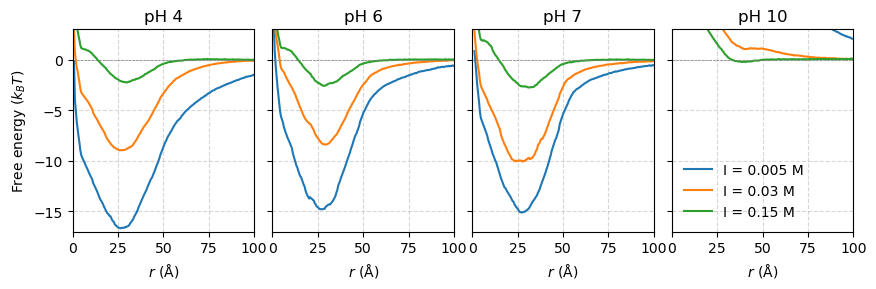

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(9, 3), sharex=True, sharey=True)

def plot_pmf(pH, ax):
    for (ionic, p), row in data.iterrows():
        if p != pH or row["pmf"] is None:
            continue
        pmf = row["pmf"]
        gofr = np.exp(-pmf.pmf_kT)
        #ax.fill_between(pmf.r, pmf.p8f_kT - pmf.stderr_kT, pmf.pmf_kT + pmf.stderr_kT, alpha=0.2)
        ax.plot(pmf.r, pmf.pmf_kT, label=f"I = {ionic:g} M")
    ax.axhline(0, color="gray", ls="--", lw=0.5)
    ax.set_xlabel(r"$r$ (Å)")
    ax.set_title(f"pH {pH:g}")

ax[0].set_xlim(0,100)
ax[0].set_ylim(-17,3)

plot_pmf(4.0, ax[0])
plot_pmf(6.0, ax[1])
plot_pmf(7.0, ax[2])
plot_pmf(10.0, ax[3])
ax[0].set_ylabel(r"Free energy ($k_BT$)")
ax[3].legend(frameon=False)
for ax in ax:
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout(w_pad=0.01) 

## Charge regulation of phytate as it approached the peptide covered interface

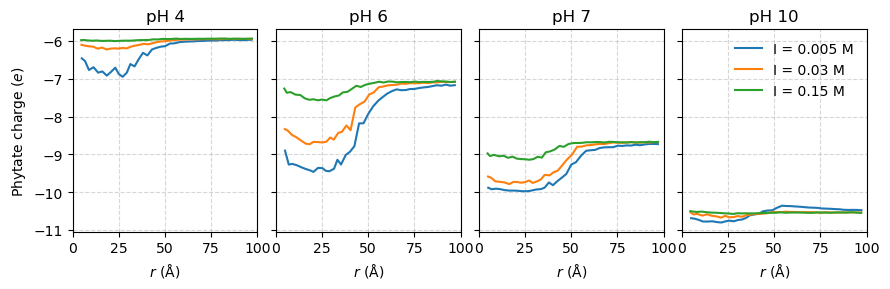

In [12]:
species = "charge_phytate"  # or "charge_peptide"

fig, ax = plt.subplots(1, 4, figsize=(9, 3), sharex=True, sharey=True)

def plot_charge(pH, ax):
    for (ionic, p), row in data.iterrows():
        if p != pH or row["charge"] is None or ionic == 1000:
            continue
        charge = row["charge"]
        ax.plot(charge.r, charge[species], label=f"I = {ionic:g} M")
    ax.set_xlabel(r"$r$ (Å)")
    ax.set_title(f"pH {pH:g}")

plot_charge(4.0, ax[0])
plot_charge(6.0, ax[1])
plot_charge(7.0, ax[2])
plot_charge(10.0, ax[3])
ax[0].set_xlim(0,100)
ax[0].set_ylabel(r"Phytate charge ($e$)")
ax[3].legend(frameon=False)
for ax in ax:
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout(w_pad=0.01)

## Phytate alignment with the decorated wall

The PolymerShape analysis acts on the rigid, disk-like phytate (`Cp ≈ 0.94`). Its
gyration tensor is reported in the lab frame (z = wall normal), with trace
`Sxx + Syy + Szz = Rg²`. The orientation relative to the wall is the P₂ order
parameter of the mass distribution about z:

$$S_\text{wall} = \tfrac{1}{2}\left(3\,S_{zz}/R_g^2 - 1\right),\qquad R_g^2 = S_{xx}+S_{yy}+S_{zz}$$

- `S_wall = 0` — isotropic (no preferred orientation)
- `S_wall < 0` (down to −½) — disk lying **face-on** (plane parallel to the wall)
- `S_wall > 0` (up to +1) — disk **edge-on** (elongated along the wall normal)

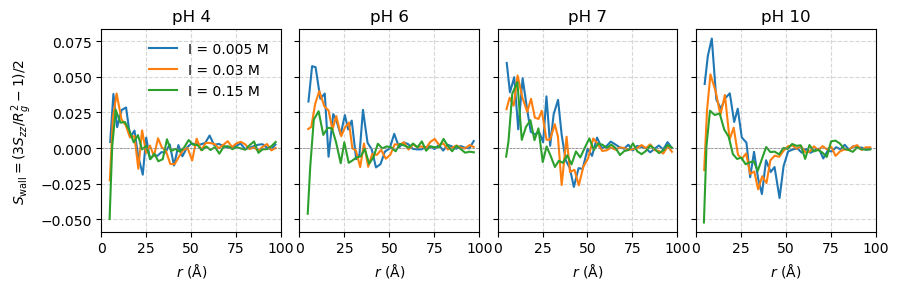

In [13]:
def wall_alignment(shape):
    """P2 order parameter of the phytate gyration tensor about the wall normal z."""
    rg2 = shape.Sxx + shape.Syy + shape.Szz
    return (3 * shape.Szz / rg2 - 1) / 2

def plot_alignment(pH, ax):
    for (ionic, p), row in data.iterrows():
        if p != pH or row["shape"] is None or ionic == 1000:
            continue
        shape = row["shape"]
        ax.plot(shape.r, wall_alignment(shape), label=f"I = {ionic:g} M")
    ax.axhline(0, color="gray", ls="--", lw=0.5)
    ax.set_xlabel(r"$r$ (Å)")
    ax.set_title(f"pH {pH:g}")

fig, ax = plt.subplots(1, 4, figsize=(9, 3), sharex=True, sharey=True)

for i, pH in enumerate([4,6,7,10]):
   plot_alignment(pH, ax[i])

ax[0].set_xlim(0,100)
ax[0].set_ylabel(r"$S_\mathrm{wall} = (3 S_{zz}/R_g^2 - 1)/2$")
ax[0].legend(frameon=False)
for ax in ax:
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout(w_pad=0.01)


## Effective electric potential due to the peptide brush (through implicit salt medium)

This is the effective electric potential felt by phytase at a given wall separation. Together with the phytate charge, this connects directly with the PMF plot.


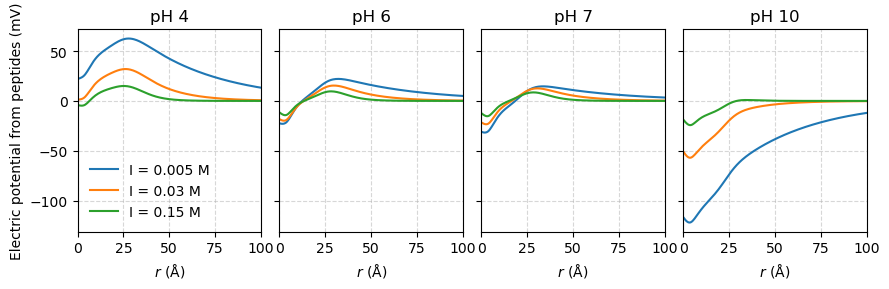

In [11]:
def plot_potential_peptide(pH, ax):
    for (ionic, p), row in data.iterrows():
        if p != pH or row["potential_peptide"] is None or ionic == 1000:
            continue
        pot = row["potential_peptide"]
        ax.plot(pot.r, pot.potential_peptide_mV, label=f"I = {ionic:g} M")
    ax.set_xlabel(r"$r$ (Å)")
    ax.set_title(f"pH {pH:g}")

fig, ax = plt.subplots(1, 4, figsize=(9, 3), sharex=True, sharey=True)

for i, pH in enumerate([4, 6, 7, 10]):
    plot_potential_peptide(pH, ax[i])

ax[0].set_xlim(0, 100)
ax[0].set_ylabel(r"Electric potential from peptides (mV)")
ax[0].legend(frameon=False)
for ax in ax:
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout(w_pad=0.01)

## Free phytate diffusion (hydrodynamic estimate)

Rough tumbling/translation of *free* phytate from RDKit conformers + PyGRPY bead hydrodynamics (stick BC, water 25 °C) — `diffusion/rotational_diffusion.py` → `diffusion/diffusion.csv`. Across protonation states (neutral → IP6¹²⁻):

- **τ_r ≈ 140–165 ps** (rotational correlation time), slowest when fully deprotonated.
- **D_rot ≈ 1.0–1.2 × 10⁹ rad²/s**, near-isotropic (D_max/D_min ≈ 1.2); **D_trans ≈ 4.4–4.7 × 10⁻¹⁰ m²/s**, Stokes radius **a_H ≈ 5.2–5.6 Å**, R_g ≈ 3.8–4.0 Å.

Net charge enters only through the bare hydrodynamic shape (peripheral H beads); ionic-atmosphere friction is not modeled and slip BC could cut τ_r by up to ~3×, so these are order-of-magnitude (τ_r ~ 10² ps). The tumbling time (~10⁻¹⁰ s) is far faster than diffusion across the brush PMF, so phytate orientation is effectively equilibrated along the reaction coordinate.